<a href="https://colab.research.google.com/github/leopapuma/caminata-aleatoria-sobre-un-grafo-/blob/main/caminata_aleatorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2196F3; text-align:center;">
tarea 2:caminata aleatoria sobre un grafo
</h1>

**se usuran las siguientes librerias para resolver el problema **

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**construimos el codigo para defenir cuales cadeneas seran buenas **

In [2]:
def es_buena(cadena):  # construimos la funcion que va recibir las cadenas
    for i in range(len(cadena) - 1): # en esta linea va recoorre las posiciones esta la penultima
        if cadena[i] == '1' and cadena[i + 1] == '1':
            return False # esta parte indicara si la cadena no es buena
    return True # si ternima la cadena se considerada que es una buena cadena

**construiremos ahora la caminata aleatoria **

In [3]:
def caminata_aleatoria(m=4, pasos=500000, calentamiento=10000, semilla=42): # construimos una cadena de m=4, se usuaran 5000000 de iteraciones
# se usara calentamiento=10000 para reducir los pasos iniciales para que no tenga mucha influenccia el estado inicial

    rng = np.random.default_rng(semilla)

    # establecemos el estado inicial
    cadena = ['0'] * m

    #  aqui vamos a guardar el numero observado de los pasos
    resultados = []

    for paso in range(pasos + calentamiento):

        #  en esta linia va eleguir aleatoriamete la poscion entre 0 y 3
        i = rng.integers(0, m)

        if cadena[i] == '1':

            #  si es uno se cambiara  a 0
            cadena[i] = '0'

        else:

            # Si es 0 se cambiara a 1
            candidata = cadena.copy()
            candidata[i] = '1'

            # solo se aceptara el cambio si es bueno
            if es_buena(candidata):
                cadena = candidata

        # descartaremos  los pasos iniciales de calentamiento
        if paso >= calentamiento:
            resultados.append(cadena.count('1'))

    return np.array(resultados)

**obtenemos el valor medio esperado **
El valor esperado se estima mediante:



In [4]:
resultados = caminata_aleatoria()

esperanza_estimada = np.mean(resultados) # obtenemos la esperanza

print("Número esperado de unos:", esperanza_estimada)

Número esperado de unos: 1.250934


obtuvimos una media de 1.2509, pero vamos a redondiar tendremos 1.25

**graficamos la convergencia**

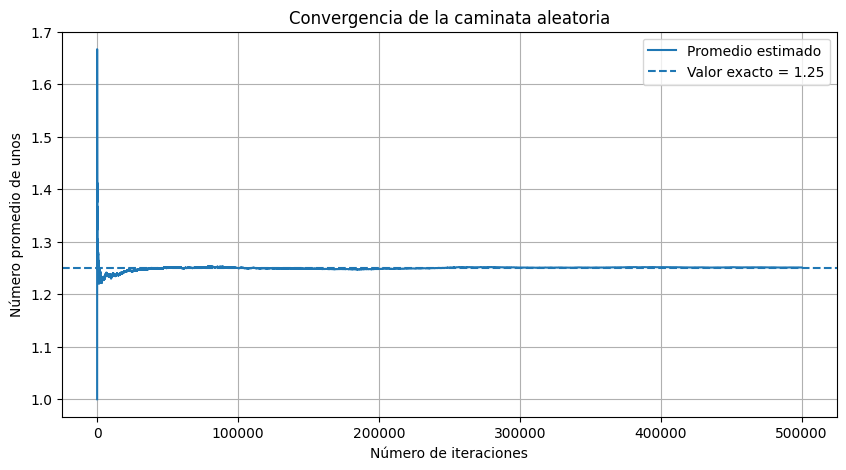

In [5]:
promedio_acumulado = np.cumsum(resultados) / np.arange(1, len(resultados) + 1) # calculamos la suma acumulada de los numeros que den unos
#graficamos
plt.figure(figsize=(10, 5))
plt.plot(promedio_acumulado, label="Promedio estimado")
plt.axhline(y=1.25, linestyle="--", label="Valor exacto = 1.25")

plt.xlabel("Número de iteraciones")
plt.ylabel("Número promedio de unos")
plt.title("Convergencia de la caminata aleatoria")
plt.legend()
plt.grid(True)
plt.show()

se puede observar quue atraves de las iteraciones se acerca el valor exacto que redondiando es 1.25

**ahora vamos a comprobar el resultado que obtuvimos con el resultado exacto **

In [6]:
from itertools import product

cadenas = [
    ''.join(bits)
    for bits in product('01', repeat=4)
    if es_buena(bits)
]

unos_por_cadena = [cadena.count('1') for cadena in cadenas]

esperanza_exacta = np.mean(unos_por_cadena)

print("Buenas cadenas:", cadenas)
print("Número de buenas cadenas:", len(cadenas))
print("Esperanza exacta:", esperanza_exacta)

Buenas cadenas: ['0000', '0001', '0010', '0100', '0101', '1000', '1001', '1010']
Número de buenas cadenas: 8
Esperanza exacta: 1.25


se obtuvo 8 buenas cadenas que son ['0000', '0001', '0010', '0100', '0101', '1000', '1001', '1010'] y nuestra media exacta es de 1.25